# Controlled signal discovery results

This notebook compares full-list rankers (Random, MiniLM, and Strands Decider) with the Strands Decider graph-search variants: model-selected root and oracle-known root. Graph search reranks the discovered shortlist using the intent plus graph-search history. The candidate catalog is the standard 39-signal RelAmazon schema-only pool. Any relevant signal not discovered counts as not retrieved; the ideal nDCG and recall denominators still use all qrels. The builder copies schema metadata only, not source records. This notebook reads saved results; it does not rerun models.

The suite covers direct attributes, one- and two-hop paths, relationship-only signals, multiple relevant signals, distractors, AND/OR logic, and temporal cases. Grades are author-defined synthetic qrels—not human-validated judgments—so this is a controlled capability check, not evidence of performance on real user conditions. The two nDCG heatmaps show path-exact scores and, as a diagnostic only, provenance-soft scores that collapse alternate paths to the same underlying attribute or relationship. The final Strands prompt receives the user intent and a summary of graph-search history, not the full schema. Its probabilities are conditional on the discovered shortlist; undiscovered candidates remain unretrieved.

In [1]:
from pathlib import Path
import json
import os
MPL_CONFIG = Path("/tmp/simbench-matplotlib")
MPL_CONFIG.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CONFIG))
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

RUN_LABELS = {
    "catalog-rank/random": "catalog-rank / random",
    "catalog-rank/minilm": "catalog-rank / minilm",
    "catalog-rank/strands-decider": "catalog-rank / Strands Decider",
    "graph-search/strands-decider": "graph-search / Strands Decider",
    "graph-search-oracle-root/strands-decider": "graph-search-oracle-root / Strands Decider",
}
METHOD_ORDER = list(RUN_LABELS)

def plot_with_oracle_root_delta(frame, method_col, metrics, title, ylabel, figsize, metric_axis=False):
    from matplotlib.patches import Patch
    oracle_pairs = {"graph-search / Strands Decider": "graph-search-oracle-root / Strands Decider"}
    labels = [str(value) for value in frame[method_col].dropna().tolist()]
    methods = list(dict.fromkeys(label for label in labels if not label.endswith("oracle-root / Strands Decider")))
    fig, ax = plt.subplots(figsize=figsize)
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    delta_handles = []
    if metric_axis:
        positions = list(range(len(metrics)))
        width = 0.8 / max(1, len(methods))
        for method_index, method in enumerate(methods):
            rows = frame.loc[frame[method_col].astype(str) == method]
            if rows.empty:
                continue
            row = rows.iloc[0]
            values = [float(row[metric]) for metric in metrics]
            offset = (method_index - (len(methods) - 1) / 2) * width
            color = colors[method_index % len(colors)]
            ax.bar([position + offset for position in positions], values, width, label=method, color=color)
            if method in oracle_pairs:
                oracle_rows = frame.loc[frame[method_col].astype(str) == oracle_pairs[method]]
                if not oracle_rows.empty:
                    oracle_values = oracle_rows.iloc[0]
                    for position, base, metric in zip(positions, values, metrics):
                        oracle = float(oracle_values[metric])
                        ax.bar(position + offset, abs(oracle - base), width, bottom=min(base, oracle), facecolor="none", edgecolor=color, hatch="....", linewidth=1.2, zorder=4)
        ax.set_xticks(positions, metrics)
        ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        positions = list(range(len(methods)))
        width = 0.8 / max(1, len(metrics))
        for metric_index, metric in enumerate(metrics):
            values = [float(frame.loc[frame[method_col].astype(str) == method, metric].iloc[0]) for method in methods]
            offset = (metric_index - (len(metrics) - 1) / 2) * width
            color = colors[metric_index % len(colors)]
            ax.bar([position + offset for position in positions], values, width, label=metric, color=color)
            for graph_method, oracle_method in oracle_pairs.items():
                oracle_rows = frame.loc[frame[method_col].astype(str) == oracle_method]
                if graph_method in methods and not oracle_rows.empty:
                    graph_index = methods.index(graph_method)
                    base = values[graph_index]
                    oracle = float(oracle_rows.iloc[0][metric])
                    ax.bar(positions[graph_index] + offset, abs(oracle - base), width, bottom=min(base, oracle), facecolor="none", edgecolor=color, hatch="....", linewidth=1.2, zorder=4)
        ax.set_xticks(positions, methods)
        ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=25, ha="right")
    has_oracle_comparison = any(graph in methods and not frame.loc[frame[method_col].astype(str) == oracle].empty for graph, oracle in oracle_pairs.items())
    if has_oracle_comparison:
        delta_handles.append(Patch(facecolor="white", edgecolor="0.25", hatch="....", label="Oracle-root delta"))
        handles, legend_labels = ax.get_legend_handles_labels()
        ax.legend(handles + delta_handles, legend_labels + ["Oracle-root delta"], title="Run" if metric_axis else "Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

RESULT_DIR = Path("/storage/lcostes/Similarity_benchmark/results/rel-amazon/controlled-signal-discovery/v2")
RUN_FILES = {
    "catalog-rank/random": (RESULT_DIR / "catalog-rank-random-summary.json", RESULT_DIR / "catalog-rank-random-summary-tasks.jsonl"),
    "catalog-rank/minilm": (RESULT_DIR / "catalog-rank-minilm-summary.json", RESULT_DIR / "catalog-rank-minilm-summary-tasks.jsonl"),
    "catalog-rank/strands-decider": (RESULT_DIR / "catalog-rank-strands-decider-summary.json", RESULT_DIR / "catalog-rank-strands-decider-summary-tasks.jsonl"),
    "graph-search/strands-decider": (RESULT_DIR / "graph-search-strands-decider-summary.json", RESULT_DIR / "graph-search-strands-decider-summary-tasks.jsonl"),
    "graph-search-oracle-root/strands-decider": (RESULT_DIR / "graph-search-oracle-root-strands-decider-summary.json", RESULT_DIR / "graph-search-oracle-root-strands-decider-summary-tasks.jsonl"),
}
summary = {"benchmark": None, "runs": {}}
task_rows = []
for run_id, (summary_path, tasks_path) in RUN_FILES.items():
    if not summary_path.is_file() or not tasks_path.is_file():
        print(f"Missing {run_id}: {summary_path} or {tasks_path}")
        continue
    payload = json.loads(summary_path.read_text(encoding="utf-8"))
    expected_strategy, expected_backend = run_id.split("/", 1)
    if payload.get("strategy") != expected_strategy:
        raise ValueError(f"{summary_path}: expected strategy {expected_strategy!r}")
    if set(payload.get("backends", {})) != {expected_backend}:
        raise ValueError(f"{summary_path}: expected only backend {expected_backend!r}")
    summary["benchmark"] = summary["benchmark"] or payload.get("benchmark")
    summary["runs"][run_id] = payload["backends"][expected_backend]
    rows = [json.loads(line) for line in tasks_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    for row in rows:
        if row.get("strategy") != expected_strategy or row.get("backend") != expected_backend:
            raise ValueError(f"{tasks_path}: inconsistent strategy/backend metadata")
        row["run"] = run_id
    task_rows.extend(rows)
    print(f"Loaded {RUN_LABELS[run_id]} from {summary_path}")
if not task_rows:
    raise FileNotFoundError(f"No controlled-result task files found under {RESULT_DIR}")
task_count = len({row["task_id"] for row in task_rows})
run_ids = [run_id for run_id in METHOD_ORDER if run_id in summary["runs"]]
summary["runs"] = {run_id: summary["runs"][run_id] for run_id in run_ids}
print(f"Benchmark: {summary["benchmark"]} | tasks: {task_count} | runs: {run_ids} | rows: {len(task_rows)} | files: {RESULT_DIR}")


Loaded Strands Decider results from /storage/lcostes/Similarity_benchmark/results/rel-amazon/controlled-signal-discovery/v2/strands-decider-e4b-summary.json
Loaded Strands graph + explored-schema rerank results from /storage/lcostes/Similarity_benchmark/results/rel-amazon/controlled-signal-discovery/v2/strands-decider-e4b-graph-summary.json
Loaded Strands graph + explored-schema rerank (oracle root) results from /storage/lcostes/Similarity_benchmark/results/rel-amazon/controlled-signal-discovery/v2/strands-decider-e4b-graph-oracle-root-summary.json
Benchmark: controlled-rel-amazon-signals-2 | tasks: 25 | scorers: ['random', 'minilm', 'strands-decider', 'strands-decider-graph-reranked', 'strands-decider-graph-reranked-oracle-root'] | rows: 125 | files: /storage/lcostes/ray-share/experiments/simbench-signals/controlled-rel-amazon-v2-ray-20261012


In [2]:
# Recompute paired path-exact and provenance-soft metrics from the saved top-five rankings.
# Soft relevance collapses path variants of one physical attribute/FK relation; duplicate cores count once.
import sys
sys.path.insert(0, '/storage/lcostes/Similarity_benchmark')
from src.synthetic.controlled_signal_metrics import ranking_metrics
BENCHMARK_DIR = Path('/storage/lcostes/ray-share/experiments/simbench-signals/controlled-rel-amazon-signals-v2')
candidate_rows = json.loads((BENCHMARK_DIR / 'candidate_catalog.json').read_text(encoding='utf-8'))
candidate_metadata = {row['id']: row for row in candidate_rows}
task_qrels = {row['id']: row['signal_grades'] for row in (json.loads(line) for line in (BENCHMARK_DIR / 'tasks.jsonl').read_text(encoding='utf-8').splitlines() if line.strip())}
for row in task_rows:
    row.update(ranking_metrics([signal['id'] for signal in row['top_signals']], task_qrels[row['task_id']], candidate_metadata))
dual_metrics = [c for c in task_rows[0] if c.startswith(('path_exact_', 'provenance_soft_'))]
for scorer in summary['runs']:
    subset = [row for row in task_rows if row['run'] == scorer]
    for metric in dual_metrics:
        summary['runs'][scorer][metric] = sum(float(row[metric]) for row in subset) / len(subset)

# Aggregate comparison, macro-averaged equally over all 25 conditions.
aggregate = pd.DataFrame.from_dict(summary['runs'], orient='index').rename_axis('run').reset_index()
aggregate['run'] = aggregate['run'].map(RUN_LABELS).fillna(aggregate['run'])
metric_columns = ['ndcg@1', 'ndcg@3', 'ndcg@5', 'recall@1', 'recall@3', 'recall@5', 'mrr']
display(aggregate[['run', 'task_count'] + metric_columns].style.format({c: '{:.3f}' for c in metric_columns}))

,scorer,task_count,ndcg@1,ndcg@3,ndcg@5,recall@1,recall@3,recall@5,mrr
0,random,25,0.080,0.090,0.106,0.060,0.120,0.140,0.192
1,minilm,25,0.000,0.053,0.053,0.000,0.080,0.080,0.106
2,strands-decider,25,0.577,0.634,0.682,0.380,0.720,0.807,0.714
3,strands-decider-graph,25,0.406,0.517,0.543,0.220,0.600,0.640,0.533
4,strands-decider-graph-oracle-root,25,0.754,0.912,0.918,0.433,1.000,1.000,0.860


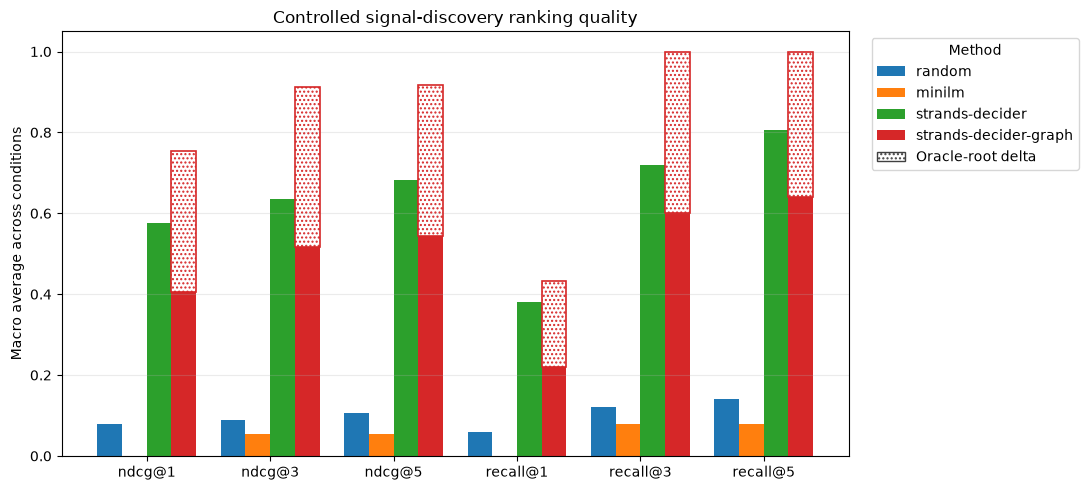

In [3]:
# Aggregate metrics. Oracle-root is shown as a dotted delta on the model-root graph bars.
plot_metrics = ['ndcg@1', 'ndcg@3', 'ndcg@5', 'recall@1', 'recall@3', 'recall@5']
plot_with_oracle_root_delta(aggregate, 'run', plot_metrics, 'Controlled signal-discovery ranking quality', 'Macro average across conditions', (11, 5), metric_axis=True)

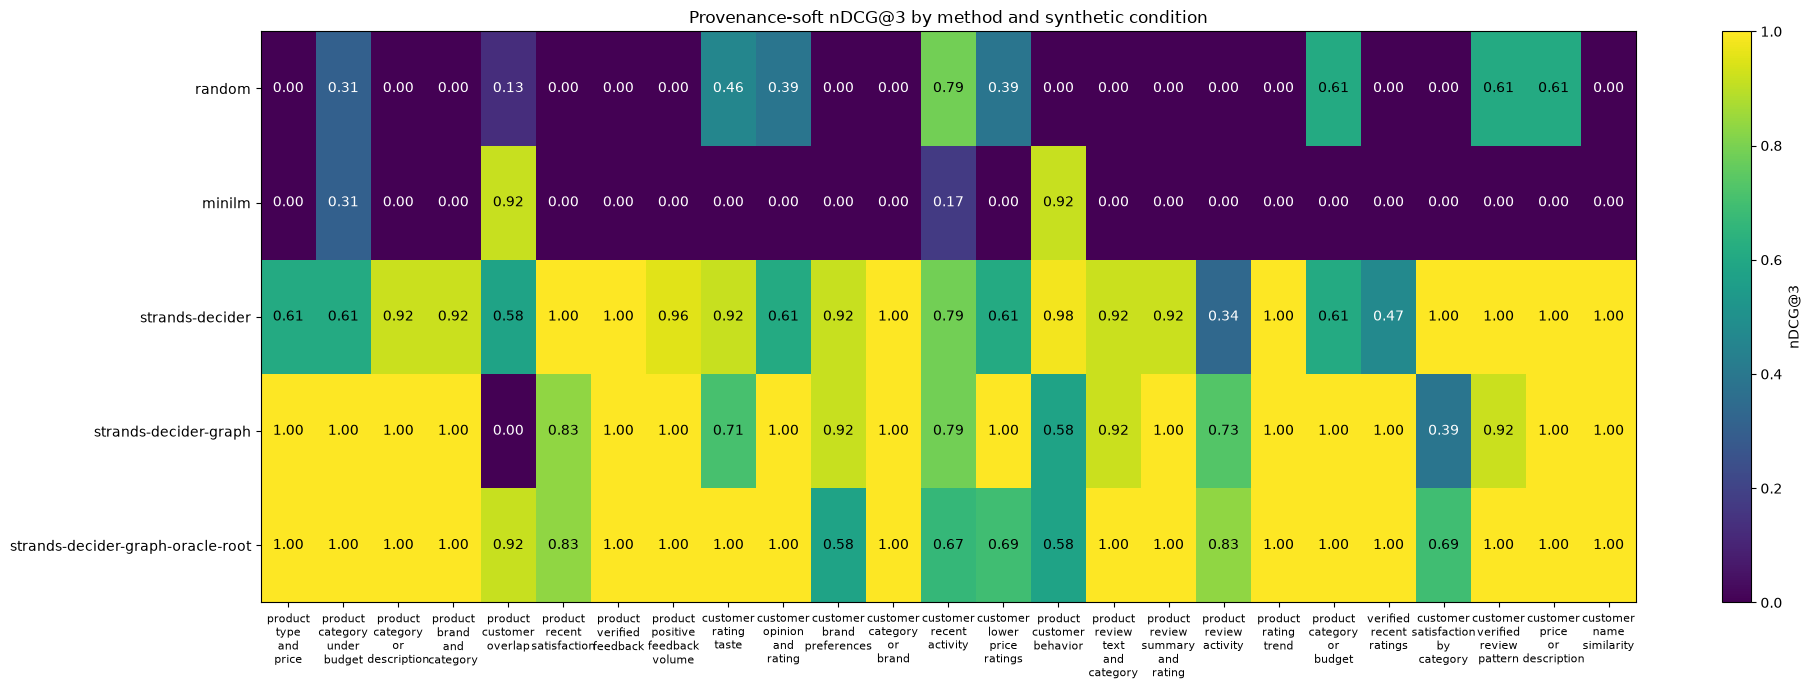

In [4]:
# Per-condition nDCG@3 view: strict path identity and provenance-soft credit.
per_task = pd.DataFrame(task_rows)
task_order = list(dict.fromkeys(per_task['task_id']))
scorer_order = [name for name in METHOD_ORDER if name in summary['runs']]
heat = per_task.pivot(index='run', columns='task_id', values='provenance_soft_ndcg@3').reindex(index=scorer_order, columns=task_order)
fig, ax = plt.subplots(figsize=(20, 7))
image = ax.imshow(heat.to_numpy(), vmin=0, vmax=1, cmap='viridis', aspect='auto')
short_labels = [task.replace('-', '\n') for task in task_order]
ax.set_xticks(range(len(task_order)), short_labels, fontsize=8)
ax.set_yticks(range(len(scorer_order)), [RUN_LABELS.get(name, name) for name in scorer_order])
ax.set_title('Provenance-soft nDCG@3 by method and synthetic condition')
for i in range(len(scorer_order)):
    for j in range(len(task_order)):
        ax.text(j, i, f'{heat.iloc[i, j]:.2f}', ha='center', va='center', color='white' if heat.iloc[i, j] < 0.55 else 'black')
fig.colorbar(image, ax=ax, label='nDCG@3')
plt.tight_layout()
plt.show()

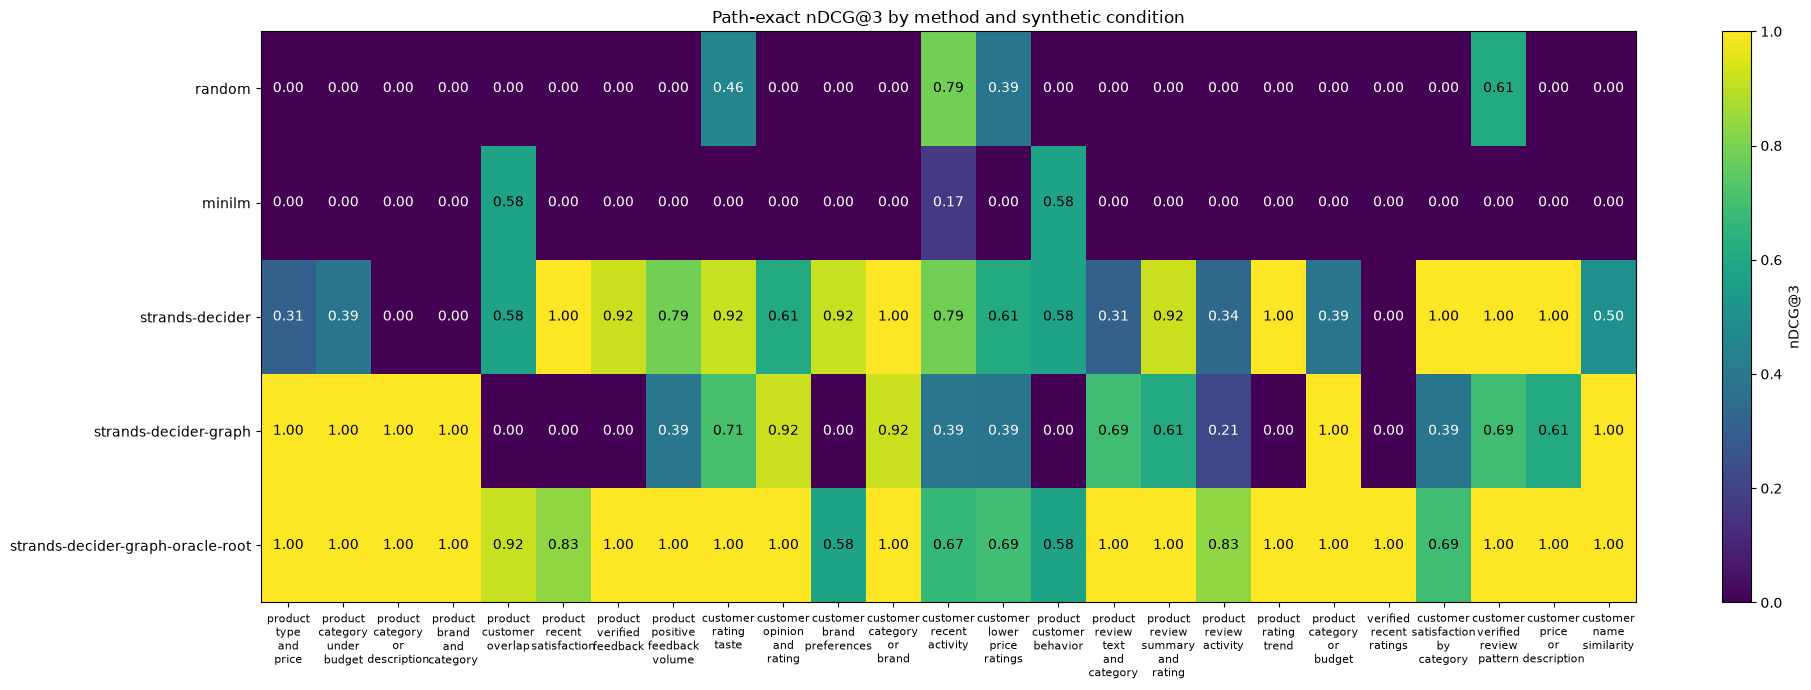

In [5]:
# Matching path-exact heatmap, using the same scale as the provenance-soft view above.
heat_exact = per_task.pivot(index='run', columns='task_id', values='path_exact_ndcg@3').reindex(index=scorer_order, columns=task_order)
fig, ax = plt.subplots(figsize=(20, 7))
image = ax.imshow(heat_exact.to_numpy(), vmin=0, vmax=1, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(task_order)), short_labels, fontsize=8)
ax.set_yticks(range(len(scorer_order)), [RUN_LABELS.get(name, name) for name in scorer_order])
ax.set_title('Path-exact nDCG@3 by method and synthetic condition')
for i in range(len(scorer_order)):
    for j in range(len(task_order)):
        ax.text(j, i, f'{heat_exact.iloc[i, j]:.2f}', ha='center', va='center', color='white' if heat_exact.iloc[i, j] < 0.55 else 'black')
fig.colorbar(image, ax=ax, label='nDCG@3')
plt.tight_layout(); plt.show()

In [6]:
# Browse the per-task method comparison.
def show_task(task_id):
    selected = per_task[per_task['task_id'] == task_id].copy()
    if selected.empty:
        raise KeyError(f'No such task: {task_id}; available: {task_order}')
    print(f"{selected.iloc[0]['reasoning_type']} | {selected.iloc[0]['condition']}")

    top_rows = []
    for _, row in selected.iterrows():
        for signal in row['top_signals']:
            top_rows.append({
                'run': row['run'],
                'reasoning type': row['reasoning_type'],
                'rank': signal['rank'],
                'grade': signal['grade'],
                'signal': signal['description'],
                'nDCG@3': row['ndcg@3'],
            })
    top_table = pd.DataFrame(top_rows)
    top_table['run'] = top_table['run'].map(RUN_LABELS).fillna(top_table['run'])
    top_table['run'] = pd.Categorical(top_table['run'], categories=[RUN_LABELS.get(name, name) for name in METHOD_ORDER], ordered=True)
    display(top_table[top_table['rank'] <= 5].sort_values(['run', 'rank']).style.format({'nDCG@3': '{:.3f}'}))

widgets.interact(show_task, task_id=widgets.Dropdown(options=task_order, description='Task'))

interactive(children=(Dropdown(description='Task', options=('product-type-and-price', 'product-category-under-…

<function __main__.show_task(task_id)>

In [7]:
# Compact per-condition metric table. Useful for copying into notes.
if 'returned_signal_count' not in per_task:
    per_task['returned_signal_count'] = per_task['candidate_count']
else:
    per_task['returned_signal_count'] = per_task['returned_signal_count'].fillna(per_task['candidate_count'])
condition_metrics = per_task[['run', 'reasoning_type', 'task_id', 'candidate_count', 'returned_signal_count', 'ndcg@3', 'recall@3', 'mrr']].copy()
condition_metrics['run'] = condition_metrics['run'].map(RUN_LABELS).fillna(condition_metrics['run'])
condition_metrics['run'] = pd.Categorical(condition_metrics['run'], categories=[RUN_LABELS.get(name, name) for name in METHOD_ORDER], ordered=True)
condition_metrics = condition_metrics.sort_values(['reasoning_type', 'task_id', 'run'])
display(condition_metrics.style.format({'ndcg@3': '{:.3f}', 'recall@3': '{:.3f}', 'mrr': '{:.3f}'}))

,scorer,reasoning_type,task_id,candidate_count,returned_signal_count,ndcg@3,recall@3,mrr
7,random,aggregation-and-relationship,product-positive-feedback-volume,39,39.000000,0.000,0.000,0.062
32,minilm,aggregation-and-relationship,product-positive-feedback-volume,39,39.000000,0.000,0.000,0.040
57,strands-decider,aggregation-and-relationship,product-positive-feedback-volume,39,39.000000,0.787,1.000,1.000
82,strands-decider-graph,aggregation-and-relationship,product-positive-feedback-volume,39,10.000000,0.394,1.000,0.333
107,strands-decider-graph-oracle-root,aggregation-and-relationship,product-positive-feedback-volume,39,10.000000,1.000,1.000,1.000
17,random,aggregation-proxy,product-review-activity,39,39.000000,0.000,0.000,0.083
42,minilm,aggregation-proxy,product-review-activity,39,39.000000,0.000,0.000,0.053
67,strands-decider,aggregation-proxy,product-review-activity,39,39.000000,0.337,0.000,0.143
92,strands-decider-graph,aggregation-proxy,product-review-activity,39,10.000000,0.213,0.000,0.167
117,strands-decider-graph-oracle-root,aggregation-proxy,product-review-activity,39,10.000000,0.834,1.000,0.500


## Reading these results

The paired heatmaps compare path-exact relevance with a provenance-soft diagnostic that treats alternate routes to the same physical attribute or FK relation as equivalent. For graph search, only discovered signals are ranked; undiscovered signals remain misses.

There are 25 curated synthetic conditions, but some reasoning categories have only one task, so per-category conclusions are not statistically robust. Inspect the heatmap and top-signal table alongside the macro average. The qrels encode the suite author's intended mapping; they do not establish which signals people prefer for real RelAmazon conditions.

### Strands Decider graph-root diagnostics

This compares Strands Decider's model-root and oracle-root graph runs. The oracle receives the authored source table; the model-root run chooses and explores roots itself.

In [8]:
strands_graph_pair = {'graph-search/strands-decider', 'graph-search-oracle-root/strands-decider'}
if strands_graph_pair <= set(per_task['run']):
    strands_model_rows = per_task[per_task['run'] == 'graph-search/strands-decider']
    if len(strands_model_rows) and isinstance(strands_model_rows.iloc[0].get('root_selection'), dict):
        root_records = pd.DataFrame([{'task_id': row['task_id'], **row['root_selection']} for _, row in strands_model_rows.iterrows()])
        correct_count = int(root_records['correct'].astype(bool).sum())
        print(f'Strands model-root accuracy: {correct_count}/{len(root_records)} = {correct_count / len(root_records):.1%} against authored source_table.')
        if 'explored_tables' in root_records:
            root_records['source_in_explored_roots'] = root_records.apply(lambda r: r['expected_table'] in r['explored_tables'], axis=1)
            hit_count = int(root_records['source_in_explored_roots'].astype(bool).sum())
            print(f'Source table included among explored roots: {hit_count}/{len(root_records)} = {hit_count / len(root_records):.1%}.')
        display(root_records[[c for c in ['task_id', 'expected_table', 'selected_table', 'explored_tables', 'choice_probability', 'correct'] if c in root_records]].style.format({'choice_probability': '{:.3f}'}))
    strands_rows = per_task[per_task['run'].isin(strands_graph_pair)]
    ndcg = strands_rows.pivot(index='task_id', columns='run', values='path_exact_ndcg@3').dropna()
    mrr = strands_rows.pivot(index='task_id', columns='run', values='mrr').reindex(ndcg.index)
    paired = pd.DataFrame({'model_root_ndcg@3': ndcg['graph-search/strands-decider'], 'oracle_root_ndcg@3': ndcg['graph-search-oracle-root/strands-decider'], 'delta_ndcg@3': ndcg['graph-search-oracle-root/strands-decider'] - ndcg['graph-search/strands-decider'], 'delta_mrr': mrr['graph-search-oracle-root/strands-decider'] - mrr['graph-search/strands-decider']})
    print(f"Strands oracle-root effect: mean paired ΔnDCG@3={paired['delta_ndcg@3'].mean():+.3f}; improved {(paired['delta_ndcg@3'] > 1e-12).sum()}/{len(paired)}, unchanged {(paired['delta_ndcg@3'].abs() <= 1e-12).sum()}/{len(paired)}, regressed {(paired['delta_ndcg@3'] < -1e-12).sum()}/{len(paired)}. Mean paired ΔMRR={paired['delta_mrr'].mean():+.3f}.")
    display(paired.sort_values('delta_ndcg@3', ascending=False).style.format('{:+.3f}'))
else:
    print('Strands model-root and oracle-root graph results are not both loaded.')

Strands model-root accuracy: 11/25 = 44.0% against authored source_table.
Source table included among explored roots: 25/25 = 100.0%.


,task_id,expected_table,selected_table,explored_tables,choice_probability,correct
0,product-type-and-price,product,product,"['product', 'customer', 'review']",0.927,True
1,product-category-under-budget,product,product,"['product', 'customer', 'review']",0.924,True
2,product-category-or-description,product,product,"['product', 'review', 'customer']",0.919,True
3,product-brand-and-category,product,product,"['product', 'customer', 'review']",0.928,True
4,product-customer-overlap,product,review,"['review', 'customer', 'product']",0.498,False
5,product-recent-satisfaction,product,review,"['review', 'product', 'customer']",0.651,False
6,product-verified-feedback,product,review,"['review', 'product', 'customer']",0.681,False
7,product-positive-feedback-volume,product,review,"['review', 'product', 'customer']",0.591,False
8,customer-rating-taste,customer,customer,"['customer', 'review', 'product']",0.550,True
9,customer-opinion-and-rating,customer,review,"['review', 'customer', 'product']",0.506,False


Strands oracle-root effect: mean paired ΔnDCG@3=+0.394; improved 19/25, unchanged 6/25, regressed 0/25. Mean paired ΔMRR=+0.327.


,model_root_ndcg@3,oracle_root_ndcg@3,delta_ndcg@3,delta_mrr
task_id,,,,
verified-recent-ratings,+0.000,+1.000,+1.000,+1.000
product-verified-feedback,+0.000,+1.000,+1.000,+1.000
product-rating-trend,+0.000,+1.000,+1.000,+1.000
product-customer-overlap,+0.000,+0.917,+0.917,+1.000
product-recent-satisfaction,+0.000,+0.834,+0.834,+0.500
product-review-activity,+0.213,+0.834,+0.621,+0.333
product-positive-feedback-volume,+0.394,+1.000,+0.606,+0.667
product-customer-behavior,+0.000,+0.579,+0.579,+0.500
customer-brand-preferences,+0.000,+0.579,+0.579,+0.500
